In [8]:
# read the two json files and visualize the content:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

with open('metrics_export_random_pop_enhanced_fixed.json', 'r') as f:
    data1 = json.load(f)
    
with open('lightfm_hybrid_evaluation_results_256d.json', 'r') as f:
    data2 = json.load(f)

In [9]:
data1

{'Random': {'10': {'hitrate': 0.0023,
   'precision': 0.0002,
   'ndcg': 0.0003,
   'coverage': 1.0,
   'gini': 0.1352},
  '20': {'hitrate': 0.0045,
   'precision': 0.0002,
   'ndcg': 0.0005,
   'coverage': 1.0,
   'gini': 0.0964},
  '50': {'hitrate': 0.0111,
   'precision': 0.0002,
   'ndcg': 0.0009,
   'coverage': 1.0,
   'gini': 0.061},
  '100': {'hitrate': 0.0214,
   'precision': 0.0002,
   'ndcg': 0.0014,
   'coverage': 1.0,
   'gini': 0.0433}},
 'Popularity': {'10': {'hitrate': 0.0302,
   'precision': 0.0032,
   'ndcg': 0.0047,
   'coverage': 0.0011,
   'gini': 0.9996},
  '20': {'hitrate': 0.0539,
   'precision': 0.0029,
   'ndcg': 0.0066,
   'coverage': 0.0019,
   'gini': 0.9993},
  '50': {'hitrate': 0.1116,
   'precision': 0.0025,
   'ndcg': 0.0108,
   'coverage': 0.0032,
   'gini': 0.9981},
  '100': {'hitrate': 0.1828,
   'precision': 0.0022,
   'ndcg': 0.0155,
   'coverage': 0.0037,
   'gini': 0.9963}},
 'EnhancedTFIDF': {'10': {'hitrate': 0.0632,
   'precision': 0.0138,
   '

In [10]:
data2

{'nDCG': {'10': 0.026306991363919917,
  '20': 0.0344999679728261,
  '50': 0.04945406627370315,
  '100': 0.06385285614423557},
 'HitRate': {'10': 0.15501022494887526,
  '20': 0.24124421483155742,
  '50': 0.3947691314175008,
  '100': 0.5320632870519858},
 'Precision': {'10': 0.01759767516951887,
  '20': 0.014683026584867108,
  '50': 0.011168227316758064,
  '100': 0.008694220213109382},
 'Coverage': {'10': 0.5227047100783174,
  '20': 0.6797808581828878,
  '50': 0.866382321579586,
  '100': 0.9551053425010111},
 'Gini': {'10': 0.9063800461983597,
  '20': 0.8783741455304563,
  '50': 0.827518670867099,
  '100': 0.7753636364676096}}

In [11]:
# 2. Transform data2 into the 'HybridMF' structure
hybrid_mf_data = {}
ks = ['10', '20', '50', '100']

for k in ks:
    hybrid_mf_data[k] = {
        # Mapping lowercase keys to match data1 format
        'ndcg': data2['nDCG'][k],
        'hitrate': data2['HitRate'][k],
        'precision': data2['Precision'][k],
        'coverage': data2['Coverage'][k],
        'gini': data2['Gini'][k]
    }


In [12]:
# 3. Combine Dictionaries
combined_data = data1.copy()
combined_data['HybridMF'] = hybrid_mf_data

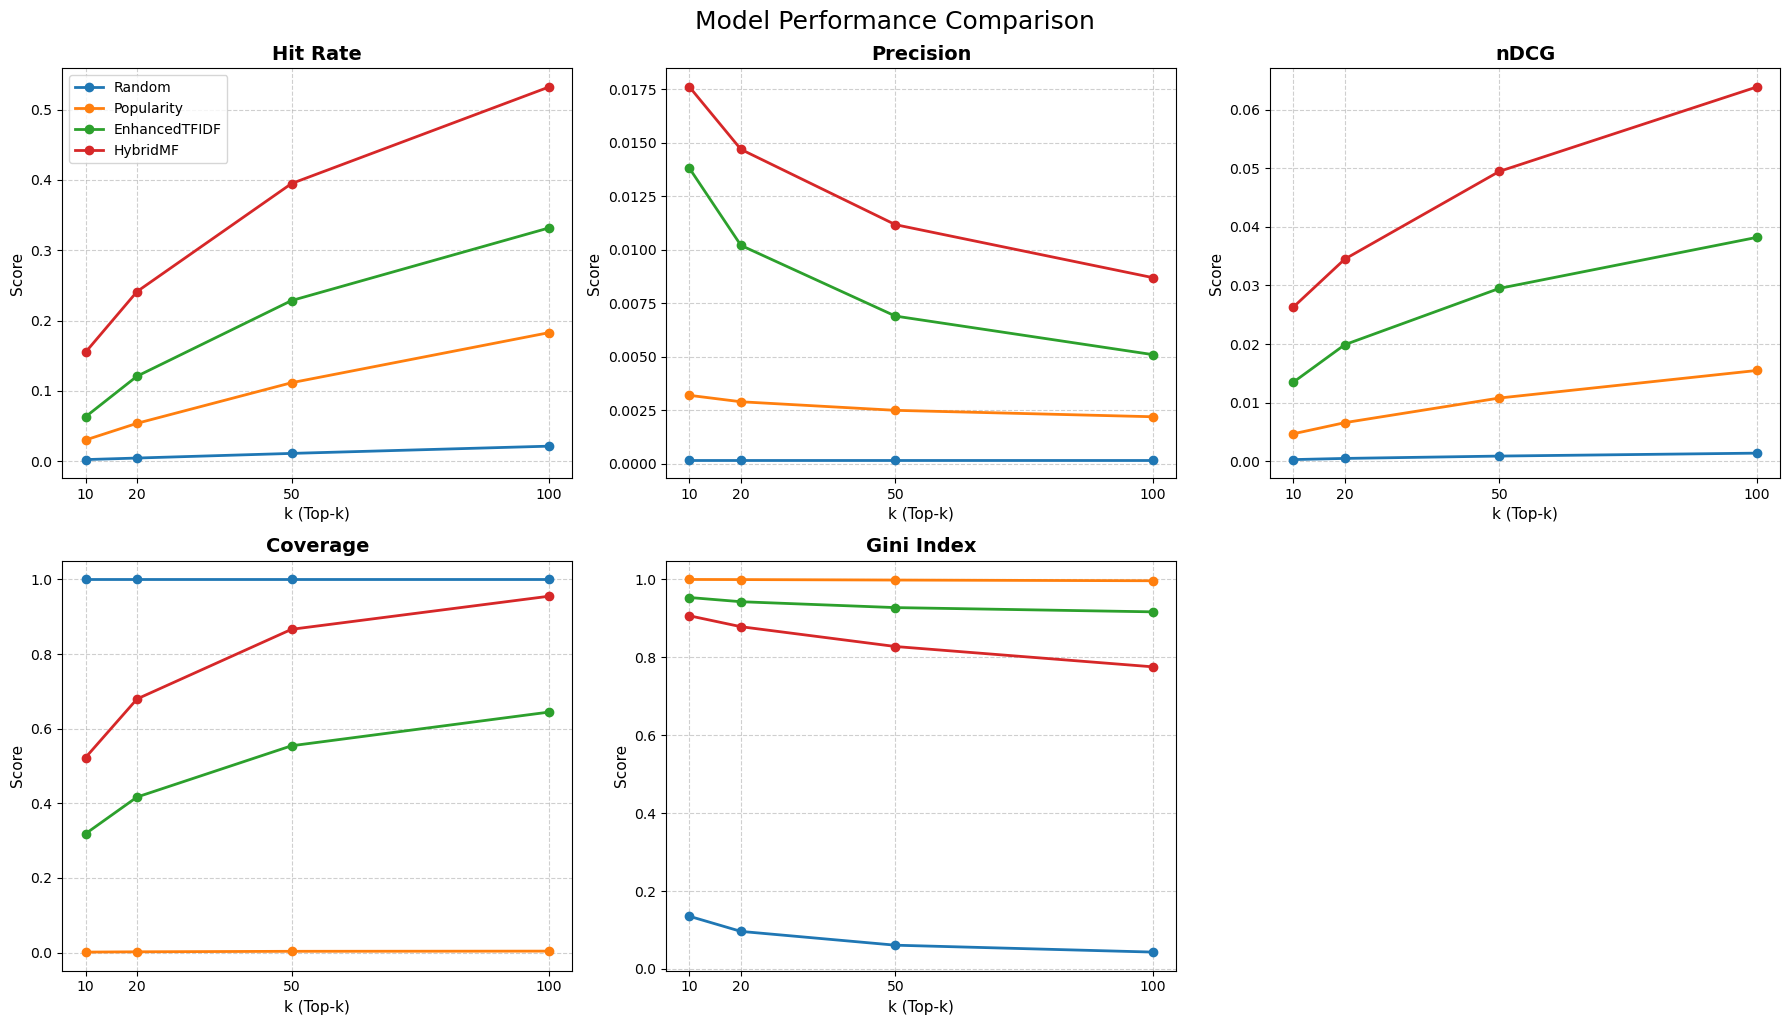

In [13]:
# ---------------------------------------------------------
# 4. Visualization Logic
# ---------------------------------------------------------

# Define metrics to plot (keys used in the inner dicts)
metrics = ['hitrate', 'precision', 'ndcg', 'coverage', 'gini']
metric_titles = ['Hit Rate', 'Precision', 'nDCG', 'Coverage', 'Gini Index']
models = list(combined_data.keys())
k_values = [10, 20, 50, 100]

# Setup plot layout (2 rows, 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Iterate over each metric to create a subplot
for i, metric in enumerate(metrics):
    ax = axes[i]
    
    for model in models:
        # Extract y-values for this model and metric across k=10, 20, 50, 100
        y_values = [combined_data[model][str(k)][metric] for k in k_values]
        
        # Plot line
        ax.plot(k_values, y_values, marker='o', label=model, linewidth=2)

    ax.set_title(metric_titles[i], fontsize=14, fontweight='bold')
    ax.set_xlabel('k (Top-k)', fontsize=11)
    ax.set_ylabel('Score', fontsize=11)
    ax.set_xticks(k_values)
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # Only add legend to the first plot to avoid clutter, or add to all if preferred
    if i == 0:
        ax.legend(loc='upper left', fontsize=10)

# Remove the empty 6th subplot (since we have 5 metrics)
fig.delaxes(axes[5])

# Add a shared legend if not adding to individual plots (optional, using space from deleted ax)
handles, labels = axes[0].get_legend_handles_labels()
axes[5].legend(handles, labels, loc='center', fontsize=12, title="Models")
axes[5].axis('off') # Keep it off but show legend

plt.tight_layout()
plt.suptitle('Model Performance Comparison', fontsize=18, y=1.02)
plt.show()

/var/folders/84/sbq4d0yx2vdcrx0_5_cy2hmh0000gn/T/ipykernel_92951/1692524312.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(models, rotation=30, ha='right', fontsize=9)
/var/folders/84/sbq4d0yx2vdcrx0_5_cy2hmh0000gn/T/ipykernel_92951/1692524312.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(models, rotation=30, ha='right', fontsize=9)
/var/folders/84/sbq4d0yx2vdcrx0_5_cy2hmh0000gn/T/ipykernel_92951/1692524312.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(models, rotation=30, ha='right', fontsize=9)
/var/folders/84/sbq4d0yx2vdcrx0_5_cy2hmh0000gn/T/ipykernel_92951/1692524312.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. a

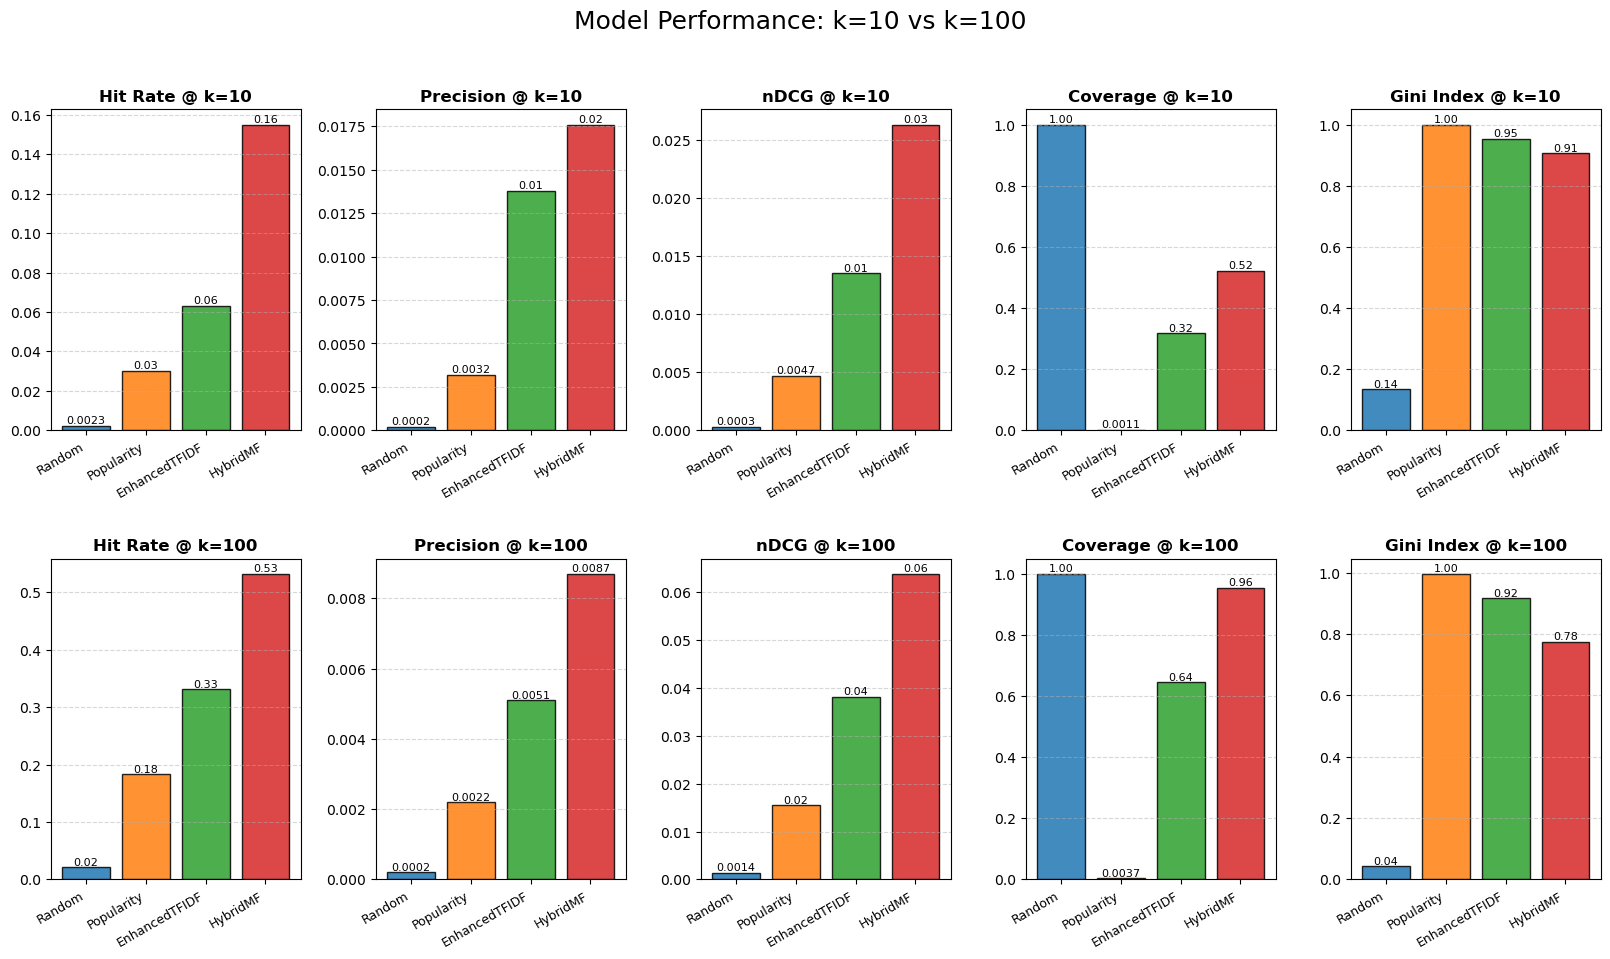

In [14]:
# ---------------------------------------------------------
# 2. Visualization Logic (Bar Charts)
# ---------------------------------------------------------

models = list(combined_data.keys())
metrics = ['hitrate', 'precision', 'ndcg', 'coverage', 'gini']
metric_labels = ['Hit Rate', 'Precision', 'nDCG', 'Coverage', 'Gini Index']
cutoffs = [10, 100]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] # Blue, Orange, Green, Red

fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))

for row_idx, k in enumerate(cutoffs):
    for col_idx, metric in enumerate(metrics):
        ax = axes[row_idx, col_idx]
        
        # Extract values for specific k and metric across all models
        values = [combined_data[model][str(k)][metric] for model in models]
        
        # Create Bar Chart
        bars = ax.bar(models, values, color=colors, alpha=0.85, edgecolor='black')
        
        # Formatting
        ax.set_title(f"{metric_labels[col_idx]} @ k={k}", fontsize=12, fontweight='bold')
        ax.grid(axis='y', linestyle='--', alpha=0.5)
        
        # Rotate x-labels for better readability
        ax.set_xticklabels(models, rotation=30, ha='right', fontsize=9)
        
        # Add value labels on top of bars
        for bar in bars:
            height = bar.get_height()
            # Dynamic formatting based on value size
            if height < 0.01:
                fmt = '{:.4f}'
            else:
                fmt = '{:.2f}'
            ax.text(bar.get_x() + bar.get_width() / 2, height, fmt.format(height),
                    ha='center', va='bottom', fontsize=8, color='black')

# Global Title and Layout
plt.suptitle('Model Performance: k=10 vs k=100', fontsize=18, y=0.98)
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()